## Task 1

<div dir="rtl">

### السؤال 1: Matplotlib و Seaborn
مكتبة Matplotlib تعطيني تحكم أكبر في الرسم وتفاصيله، أما Seaborn  وتخلي الرسم جاهز ومرتب وشكله واضح ومرتب بنتعلم الثنتين لأن Seaborn أسرع في الشغل، وMatplotlib تفيدنا لما نبغى نعدل على الرسمة بدقة

</div>

<div dir="rtl">

### السؤال 2: خاصية hue

</div>

<div dir="rtl">


خاصية `hue` نستخدمها عشان نلون البيانات حسب فئة معينة. مثلاً في بيانات التأمين (`insurance`) نقدر نقسم الرسمة حسب المدخنين (`smoker`)، وبكذا يوضح لنا الفرق بين المدخنين وغير المدخنين ونشوف إن المدخنين تكاليفهم الطبية أعلى بالغالب

</div>

<div dir="rtl">

### السؤال 3: الخط فوق العمود في barplot
كنت أعرف إن الخط الي فوق العمود يبين لنا وضوح المتوسط. ولو كانت الخطوط متداخلة بين الأعمدة، معناه إن الفرق بينهم مو شرط يكون حقيقي، ويمكن يكون مجرد صدفة عادية

</div>

<div dir="rtl">

### السؤال 4: المخطط الصندوقي (Boxplot)

</div>

<div dir="rtl">


الخط الي داخل الصندوق يمثل القيمة الوسطى، وحدود الصندوق هي $Q1$ و $Q3$. الصندوق نفسه يضم تقريبًا 50٪ من البيانات، والمسافة بين $Q1$ و $Q3$ هي الـ `IQR`. أما النقاط المنفصلة فتعتبر قيم شاذة لو كانت أبعد من 1.5 ضعف الـ `IQR` عن أطراف الصندوق

</div>

## Task 2

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

tips = sns.load_dataset("tips")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<div dir="rtl">

### توقعي (histplot)
أتوقع فواتير العشاء تكون أعلى من فواتير الغداء

</div>

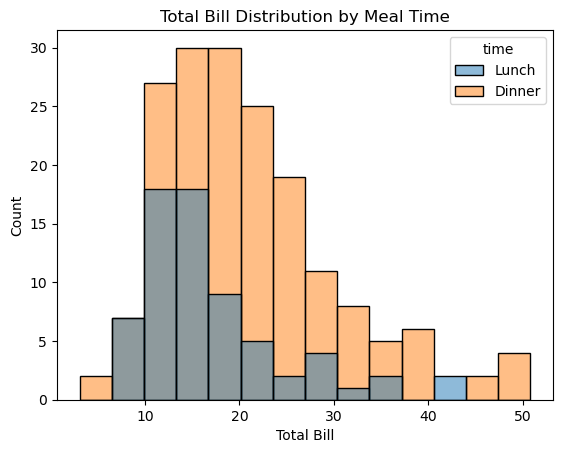

        count       mean  median
time                            
Lunch      68  17.168676  15.965
Dinner    176  20.797159  18.390


In [2]:
sns.histplot(data=tips, x="total_bill", hue="time")
plt.title("Total Bill Distribution by Meal Time")
plt.xlabel("Total Bill")
plt.ylabel("Count")
plt.show()

print(tips.groupby("time", observed=False)["total_bill"].agg(["count", "mean", "median"]))

<div dir="rtl">

### ملاحظتي (histplot)
توقعي طلع صحيح؛ توقعت إن فواتير العشاء تكون أعلى من فواتير الغداء، وبالفعل طلع متوسط فواتير العشاء 20.80 مقابل 17.17 للغداء. حتى الوسيط كان أعلى للعشاء (18.39 مقابل 15.97)، وعدد فواتير العشاء أكثر بكثير بـ 176 فاتورة مقابل 68 للغداء

وشكل التوزيع طلع منحرف لليمين لأن المتوسط أكبر من الوسيط، وايضا لاحظت عمود أزرق لحاله عند حوالي 43 يمثل فاتورة غداء عالية

</div>

<div dir="rtl">

### توقعي (boxplot)
أتوقع بعض الأيام يكون فيها بقشيش أعلى من الأيام الأخرى، وقد تظهر قيم شاذة

</div>

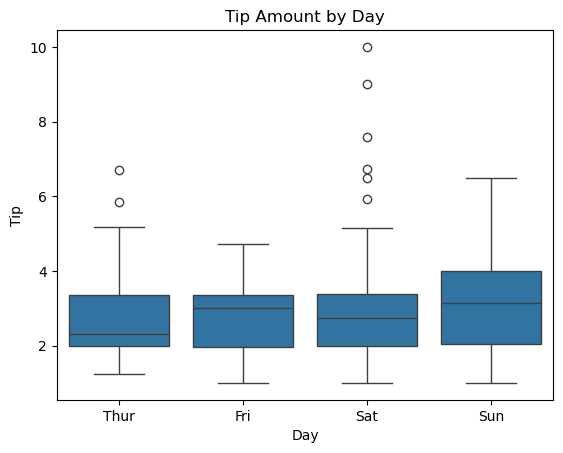

      count  median    max
day                       
Thur     62   2.305   6.70
Fri      19   3.000   4.73
Sat      87   2.750  10.00
Sun      76   3.150   6.50


In [3]:
sns.boxplot(data=tips, x="day", y="tip")
plt.title("Tip Amount by Day")
plt.xlabel("Day")
plt.ylabel("Tip")
plt.show()

print(tips.groupby("day", observed=False)["tip"].agg(["count", "median", "max"]))

<div dir="rtl">

### ملاحظتي (boxplot)
كان توقعي صحيح وأن تظهر فروقات بين الأيام وقيم شاذة، وبالفعل ظهر أن أعلى وسيط بقشيش كان يوم الأحد (`Sun`) بقيمة 3.15، بعده يوم الجمعة (`Fri`) بـ 3.00 لكن عدد فواتيره قليل (19 فاتورة فقط). كما ظهرت قيم شاذة في يومي الخميس (`Thur`) والسبت (`Sat`)، وكانت أعلى قيمة بقشيش في السبت وبلغت 10.00، وما ظهرت أي قيم شاذة في الجمعة والأحد
</div>

<div dir="rtl">

### توقعي (countplot)
أتوقع يوم السبت يكون فيه عدد فواتير أكثر من بقية الأيام، وأتوقع غير المدخنين يكون عددهم أكثر من المدخنين
</div>

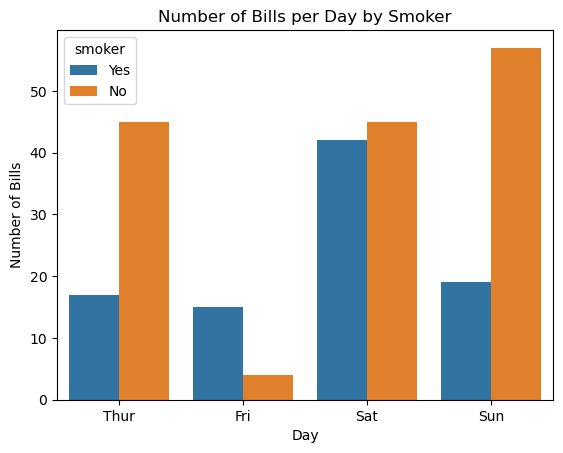

smoker  Yes  No
day            
Thur     17  45
Fri      15   4
Sat      42  45
Sun      19  57


In [4]:
sns.countplot(data=tips, x="day", hue="smoker")
plt.title("Number of Bills per Day by Smoker")
plt.xlabel("Day")
plt.ylabel("Number of Bills")
plt.show()

print(tips.groupby(["day", "smoker"], observed=False).size().unstack())

<div dir="rtl">

### ملاحظتي (countplot)
توقعي الأول كان صحيح، والثاني صحيح جزيئا:
* **التوقع الأول:** يوم السبت (`Sat`) كان الأعلى بعدد الفواتير بإجمالي 87 فاتورة (42 مدخنين و45 غير مدخنين).
* **التوقع الثاني:** عدد غير المدخنين كان أعلى في الخميس (`Thur`: 45 مقابل 17) والأحد (`Sun`: 57 مقابل 19) والسبت (`Sat`: 45 مقابل 42)، لكنه طلع غلط في يوم الجمعة (`Fri`) لأن عدد المدخنين كان 15 مقابل 4 فقط لغير المدخنين

وبشكل عام، عدد غير المدخنين كان أكثر بكثير بـ 151 فاتورة مقابل 93 فاتورة للمدخنين

</div>

<div dir="rtl">

### توقعي (scatterplot)
أتوقع كل ما قلت الفاتورة قل البقشيش

</div>

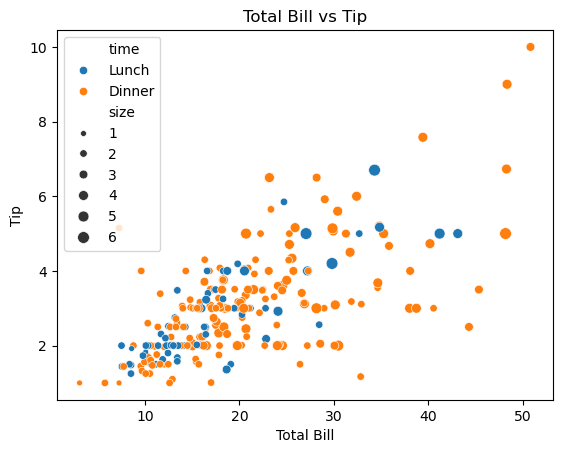

            total_bill       tip
total_bill    1.000000  0.675734
tip           0.675734  1.000000


In [5]:
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", size="size")
plt.title("Total Bill vs Tip")
plt.xlabel("Total Bill")
plt.ylabel("Tip")
plt.show()

print(tips[["total_bill", "tip"]].corr())

<div dir="rtl">

### ملاحظتي (Scatterplot)
توقعي غير صحيح كنت متوقعة إن البقشيش يقل كل ما زادت الفاتورة، بس النتيجة طلعت العكس الرسمة بينت إن العلاقة موجبة بين الفاتورة والبقشيش، ومعامل الارتباط طلع 0.675

وايضا لاحظت إن أغلب الفواتير العالية كانت في وقت العشاء (`Dinner`)، بينما نقاط الغداء (`Lunch`) تركزت عند الفواتير الأقل. والنقاط الأكبر حجمًا (اللي تمثل عدد أشخاص أكثر على الطاولة) تظهر غالبًا عند الفواتير الأعلى

</div>

<div dir="rtl">

### توقعي (barplot)
أتوقع يوم السبت يكون عنده أعلى متوسط بقشيش، وأتوقع بعض الخطوط السوداء تكون متداخلة لأن الفروق بين الأيام قد لا تكون كبيرة
</div>

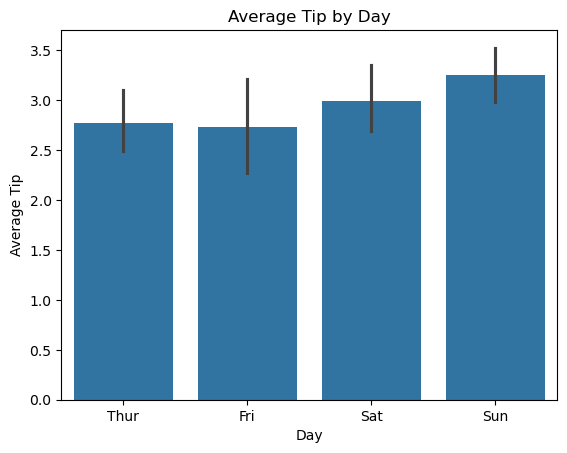

          mean       std  count
day                            
Thur  2.771452  1.240223     62
Fri   2.734737  1.019577     19
Sat   2.993103  1.631014     87
Sun   3.255132  1.234880     76


In [6]:
sns.barplot(data=tips, x="day", y="tip")
plt.title("Average Tip by Day")
plt.xlabel("Day")
plt.ylabel("Average Tip")
plt.show()

print(tips.groupby("day", observed=False)["tip"].agg(["mean", "std", "count"]))

<div dir="rtl">

### ملاحظتي (Barplot)
توقعي الأول كان غير صحيح؛ كنت متوقعة إن يوم السبت (`Sat`) يكون فيه أعلى متوسط بقشيش، بس طلع أعلى متوسط في يوم الأحد (`Sun`) بقيمة 3.255 مقابل 2.993 في السبت 

لكن توقعي الثاني فكان صحيح، لأن الخطوط السوداء اللي فوق الأعمدة طلعت متداخلة، وهذا معناه إن فترات الثقة متداخلة والفروق بين متوسطات البقشيش في الأيام مو كبيرة أو حقيقية بشكل واضح

</div>

<div dir="rtl">

### توقعي (heatmap)
أتوقع أن أقوى ارتباط يكون بين size و tip أكثر من total_bill و tip
</div>

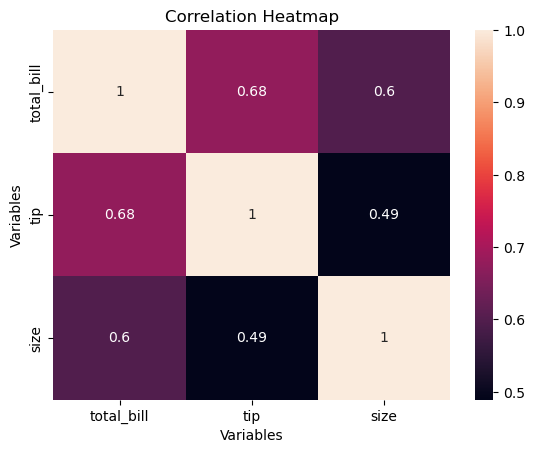

            total_bill       tip      size
total_bill    1.000000  0.675734  0.598315
tip           0.675734  1.000000  0.489299
size          0.598315  0.489299  1.000000


In [7]:
corr = tips[["total_bill", "tip", "size"]].corr()

sns.heatmap(corr, annot=True)
plt.title("Correlation Heatmap")
plt.xlabel("Variables")
plt.ylabel("Variables")
plt.show()

print(corr)

<div dir="rtl">

### ملاحظتي (heatmap)
توقعي غير صحيح؛ كنت متوقعة إن أقوى ارتباط يكون بين عدد الأشخاص (`size`) والبقشيش (`tip`)، بس النتيجة طلعت أقوى ارتباط بين قيمة الفاتورة (`total_bill`) والبقشيش (`tip`) بقيمة **0.676**، بعده الارتباط بين الفاتورة وحجم الطاولة بقيمة **0.598**، بينما الارتباط بين حجم الطاولة والبقشيش طلع هو الأضعف بقيمة **0.489**

ولاحظت من الألوان إن اللون الداكن يعني ارتباط أضعف واللون الفاتح أقوى، وشريط الألوان يبدأ من 0.5، فحتى أضعف ارتباط (0.489) لسا ارتباط متوسط موجب

</div>

## Task 3

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("loan_clean.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,1
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,0
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,1
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,1
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,1


<div dir="rtl">

### توقعي (countplot)
أتوقع أن عدد الطلبات المقبولة يكون أكثر من المرفوضة، لأن أغلب بيانات القروض بالعادة تكون موافق عليها. وأتوقع أن تكون نسبة الطلبات المقبولة بحدود 50% إلى 60% من إجمالي الطلبات

</div>

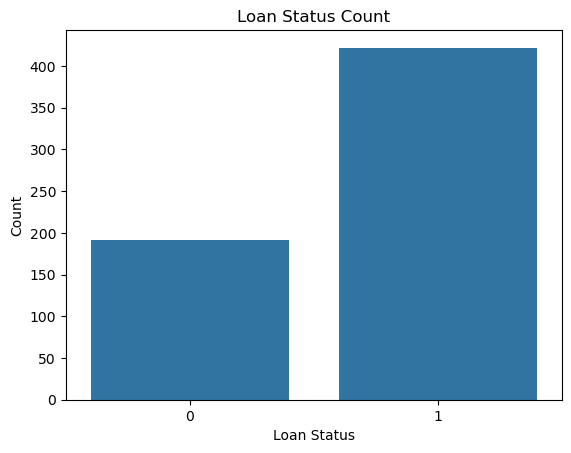

Loan_Status
1    422
0    192
Name: count, dtype: int64


In [9]:
sns.countplot(data=df, x="Loan_Status")
plt.title("Loan Status Count")
plt.xlabel("Loan Status")
plt.ylabel("Count")
plt.show()

print(df["Loan_Status"].value_counts())

<div dir="rtl">

### ملاحظتي (countplot)
* **التوقع الأول:** توقعي صحيح كنت متوقعة إن الطلبات المقبولة تكون أكثر من المرفوضة، وبالفعل طلع عدد الطلبات المقبولة 422 طلب مقابل 192 طلب مرفوض، ليصبح الإجمالي 614 طلب
* **التوقع الثاني:** توقعي غير صحيح توقعت إن نسبة القبول تكون بين 50% و60%، بس النسبة طلعت أعلى ووصلت لحوالي 69%

ولاحظت أن محور X يوضح أن 1 يعني مقبول و0 يعني مرفوض (لأن الرسمة ما توضح هالشيء بنفسها)

</div>

<div dir="rtl">

### توقعي (barplot)
أتوقع أن الأشخاص اللي عندهم سجل ائتماني (`Credit_History = 1`) تكون نسبة الموافقة لهم حوالي 60%، بينما الأشخاص الي السجل عندهم (`Credit_History = 0`) تكون نسبة الموافقة قريبة منها وأتوقع أن منطقة الريف (`Rural`) تمتلك أعلى نسبة موافقة، لأن الطلب على القروض فيها ممكن يكون أكبر

</div>

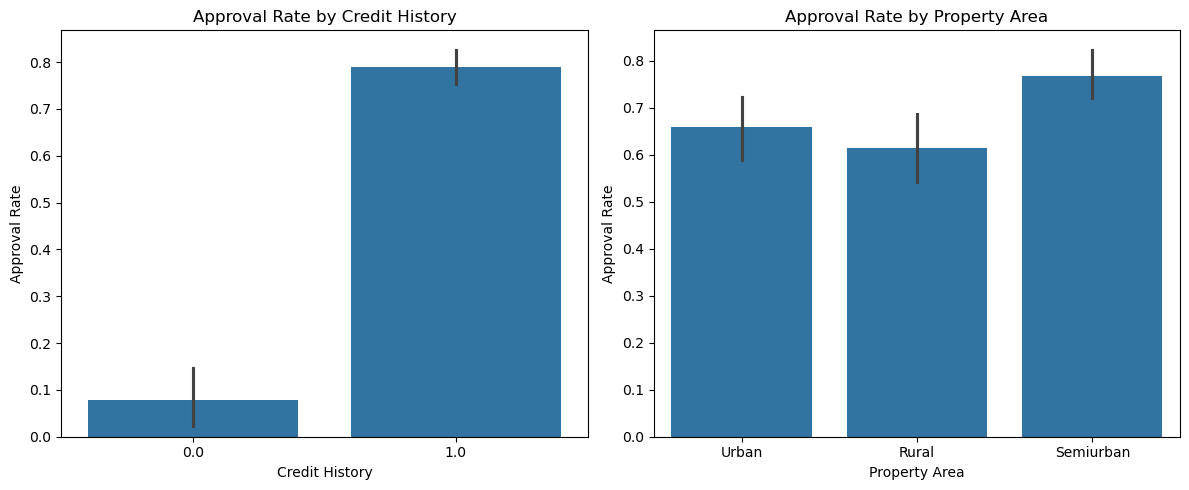

Credit_History
0.0    0.078652
1.0    0.790476
Name: Loan_Status, dtype: float64
Property_Area
Rural        0.614525
Semiurban    0.768240
Urban        0.658416
Name: Loan_Status, dtype: float64


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=df, x="Credit_History", y="Loan_Status", ax=axes[0])
axes[0].set_title("Approval Rate by Credit History")
axes[0].set_xlabel("Credit History")
axes[0].set_ylabel("Approval Rate")

sns.barplot(data=df, x="Property_Area", y="Loan_Status", ax=axes[1])
axes[1].set_title("Approval Rate by Property Area")
axes[1].set_xlabel("Property Area")
axes[1].set_ylabel("Approval Rate")

plt.tight_layout()
plt.show()

print(df.groupby("Credit_History")["Loan_Status"].mean())
print(df.groupby("Property_Area")["Loan_Status"].mean())

<div dir="rtl">

### ملاحظتي (barplot)
توقعي بخصوص السجل الائتماني كان غير صحيح لأني توقعت تقارب النصفين، لكن ظهر فرق كبير: أصحاب `Credit_History = 1` بلغت نسبتهم 79.0%، لكن أصحاب `Credit_History = 0` بلغت 7.9% فقط

وكذلك توقعي لمنطقة العقار كان غير صحيح أعلى نسبة موافقة كانت في `Semiurban` بنسبة 76.8%، بعدها `Urban` بنسبة 65.8%، وبالاخير `Rural` بنسبة 61.5%

وبالنسبة للرسمة، محور X يمثل الفئات ومحور نسبة الموافقة، والخطوط السوداء ما تداخلت بين فئات السجل الائتماني بسبب الفرق الكبير. لكن مناطق العقار فالتداخل فيها مو بسيط `Urban` و`Rural` خطوطهم متداخلة بشكل واضح يعني الفرق بينهم ممكن يكون صدفة، بينما `Semiurban` منفصلة تقريبا عن `Rural` وتلمس `Urban` بالكاد، فالفرق معها يبدو أقوى وأحق

</div>

<div dir="rtl">

### توقعي (boxplot)
أتوقع أن يكون دخل الأشخاص المقبولين أعلى من المرفوضين، لأن الدخل العالي ممكن يزيد من فرصة قبول القرض. أما بالنسبة لمبلغ القرض فأتوقع ما يكون فيه فرق كبير بين المقبولين والمرفوضين. وايضا أتوقع تظهر قيم شاذة، خصوصا في الدخل لأن بعض المتقدمين ممكن تكون رواتبهم مرتفعة مرة مقارنة بباقي الناس

</div>

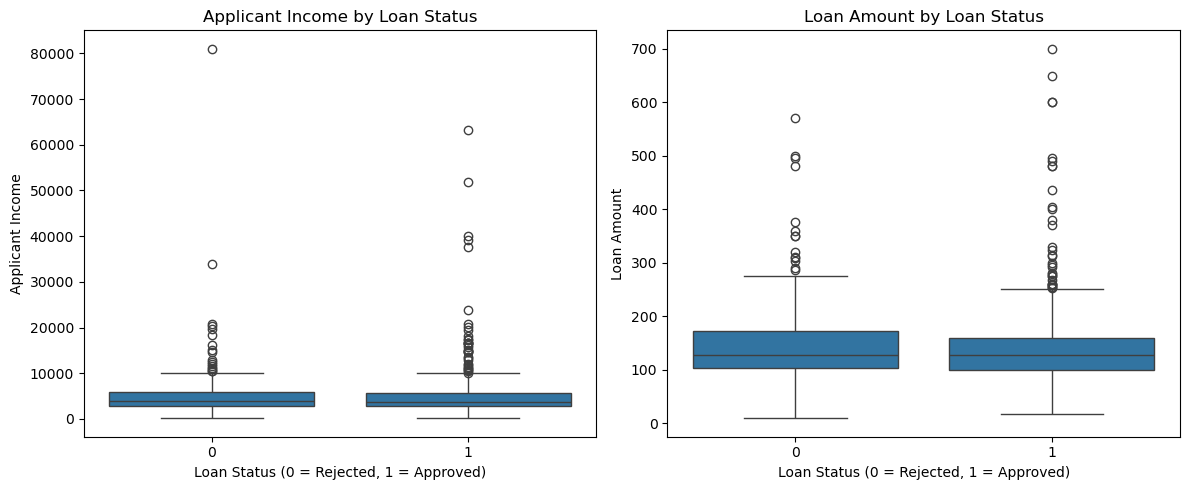

             ApplicantIncome  LoanAmount
Loan_Status                             
0                     3833.5       128.0
1                     3812.5       128.0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="Loan_Status", y="ApplicantIncome", ax=axes[0])
axes[0].set_title("Applicant Income by Loan Status")
axes[0].set_xlabel("Loan Status (0 = Rejected, 1 = Approved)")
axes[0].set_ylabel("Applicant Income")

sns.boxplot(data=df, x="Loan_Status", y="LoanAmount", ax=axes[1])
axes[1].set_title("Loan Amount by Loan Status")
axes[1].set_xlabel("Loan Status (0 = Rejected, 1 = Approved)")
axes[1].set_ylabel("Loan Amount")

plt.tight_layout()
plt.show()

print(df.groupby("Loan_Status")[["ApplicantIncome", "LoanAmount"]].median())

<div dir="rtl">

### ملاحظتي (boxplot)
توقعي الأول كان غير صحيح كنت متوقعة إن دخل المقبولين يكون أعلى من المرفوضين، بس النتيجة ما أظهرت فرق واضح، وطلع وسيط الدخل 3812.5 للمقبولين مقابل 3833.5 للمرفوضين. الصناديق تتداخل بشكل كبير بين المجموعتين، يعني الدخل لحاله ما يفسر قرار القبول (بعكس السجل الائتماني اللي شفنا فيه فرق ضخم 79% مقابل 7.9%)

لكن توقعي الثاني فكان صحيح لأن مبلغ القرض بالفعل ما اختلف بين المجموعتين وطلع الوسيط 128 في الثنتين. وكمان ظهرت قيم شاذة كثيرة في الدخل ومبلغ القرض عند المقبولين والمرفوضين، ووصلت بعض قيم الدخل لأكثر من 50,000 وبعض مبالغ القروض لقرابة 700

</div>

<div dir="rtl">

### توقعي (histplot)
أتوقع أن توزيع الدخل يكون منحرف لليمين ومو متماثل، لأن فيه ناس قليلين رواتبهم عالية مرة مقارنة بباقي المتقدمين. وأتوقع إن القيم الشاذة الكبيرة زي 80,000 تخلي الرسمة الأولى مو واضحة وتشوش أغلب البيانات في زاوية صغيرة، وأتوقع أن الرسمة الثانية (اللي تحدد الدخل أقل من 20,000) بتكون أوضح وتوضح التوزيع بشكل أحسن

</div>

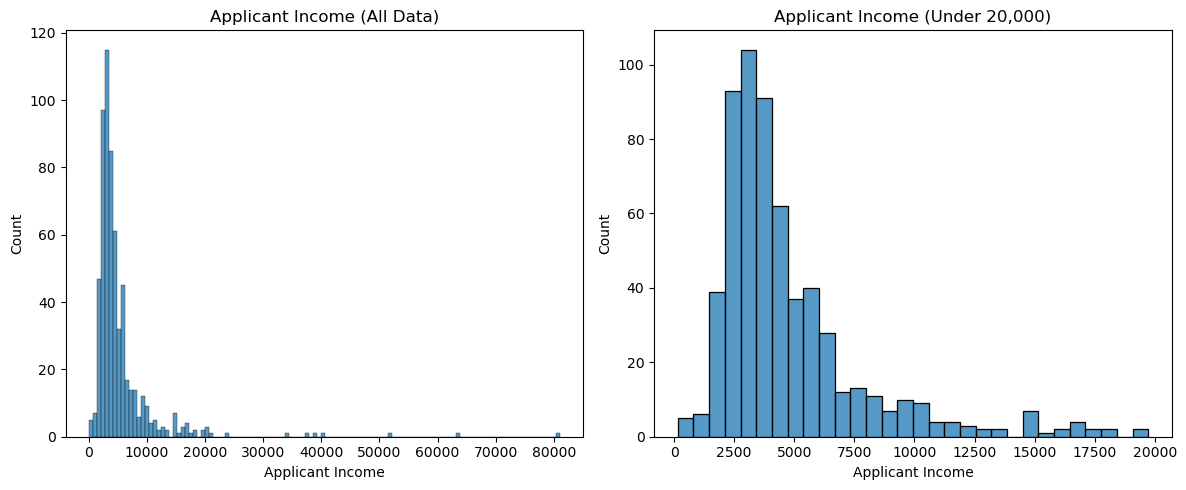

602 من 614
count      614.000000
mean      5403.459283
std       6109.041673
min        150.000000
25%       2877.500000
50%       3812.500000
75%       5795.000000
max      81000.000000
Name: ApplicantIncome, dtype: float64


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=df, x="ApplicantIncome", ax=axes[0])
axes[0].set_title("Applicant Income (All Data)")
axes[0].set_xlabel("Applicant Income")
axes[0].set_ylabel("Count")

sns.histplot(data=df[df["ApplicantIncome"] < 20000], x="ApplicantIncome", ax=axes[1])
axes[1].set_title("Applicant Income (Under 20,000)")
axes[1].set_xlabel("Applicant Income")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

print((df["ApplicantIncome"] < 20000).sum(), "من", len(df))
print(df["ApplicantIncome"].describe())

<div dir="rtl">

### ملاحظتي (histplot)
توقعي صحيح الرسمة بينت إن توزيع الدخل منحرف لليمين بسبب وجود قيم شاذة كبيرة وصلت إلى 81,000 (ويأكد هالشيء أن المتوسط 5403 أكبر من الوسيط 3812.5). ولذلك كانت الرسمة الأولى غير واضحة ، لكن الرسمة الثانية طلعت أوضح بكثير لأنها استبعدت 12 شخص بس (يعني تقريباً 2% من الداتا) وركزت على أغلب البيانات، لدرجة إن 602 شخص من أصل 614 كان دخلهم أقل من 20,000

وحتى بعد الحذف، التوزيع منحرف لليمين وأغلب الدخل يتركز تقريباً بين 2500 و5000

</div>

<div dir="rtl">

### توقعي (heatmap)
أتوقع أن أكثر عمود مرتبط مع حالة القرض (`Loan_Status`) هو السجل الئتماني (`Credit_History`) وبشكل موجب، لأن الي عندهم سجل ممتاز بالغالب فرصة قبول قروضهم تكون أعلى وأتوقع أن أضعف ارتباط يكون دخل المتقدم (`ApplicantIncome`)، لأن الدخل لحاله مو شرط يكون السبب الوحيد في قبول أو رفض القرض

</div>

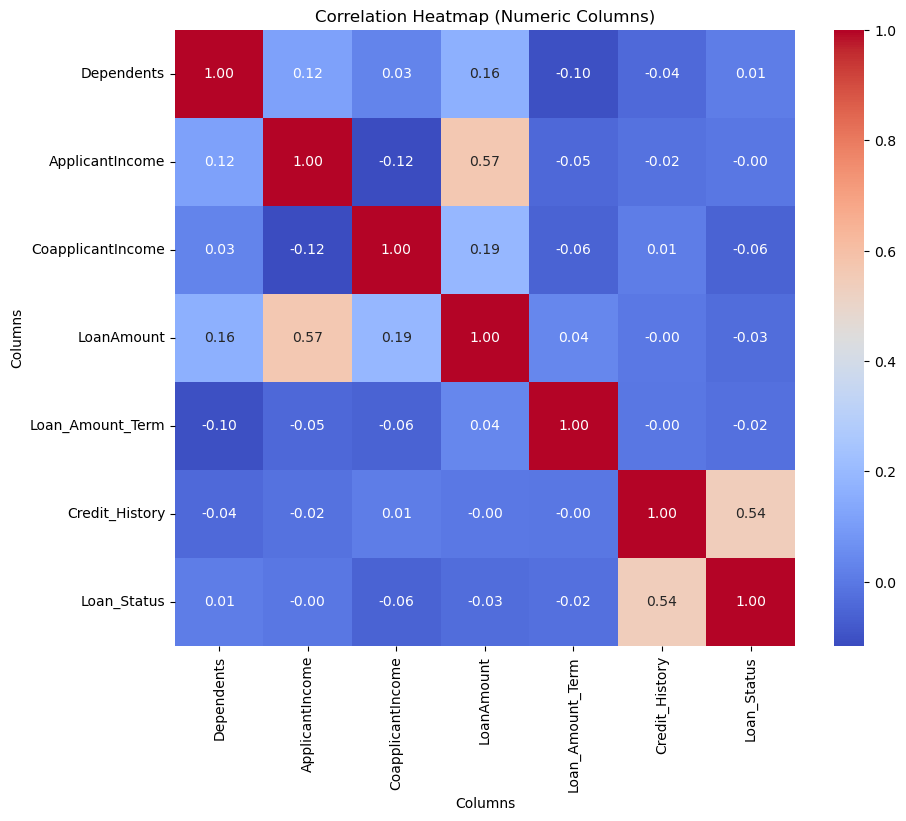

Loan_Status          1.000000
Credit_History       0.540556
Dependents           0.010118
ApplicantIncome     -0.004710
Loan_Amount_Term    -0.022549
LoanAmount          -0.033214
CoapplicantIncome   -0.059187
Name: Loan_Status, dtype: float64


In [13]:
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap (Numeric Columns)")
plt.xlabel("Columns")
plt.ylabel("Columns")
plt.show()

print(corr["Loan_Status"].sort_values(ascending=False))

<div dir="rtl">

### ملاحظتي (heatmap)
توقعي طلع صحيح السجل الئتماني (`Credit_History`) كان أكثر عمود مرتبط مع حالة القرض (`Loan_Status`) وبالفعل بلغ الارتباط 0.54. وكان دخل المتقدم (`ApplicantIncome`) هو الأضعف بارتباط سالب تقريبا (-0.005)، يعني ما فيه أي علاقة واضحة بين الدخل لحاله وقبول القرض

ولاحظت ارتباط قوي بين دخل المتقدم (`ApplicantIncome`) ومبلغ القرض (`LoanAmount`) بقيمة 0.57، وهذا معناه أن الي دخلهم أعلى يطلبون قروض بمبالغ أكبر. وهذي النتيجة تتوافق الي شفناه قبل شوي في نسبة الموافقة (79% لأصحاب `Credit_History = 1` مقابل 7.9% فقط لأصحاب `Credit_History = 0`)

</div>

<div dir="rtl">

### الجزء 6: رسمة ام رقم؟

* الرسمة الأولى (countplot): وضحت ان عدد الطلبات المقبولة اكبر من المرفوضة، والرقم اللي اكد هالشي هو 422 طلب مقبول مقابل 192 مرفوض
* الرسمة الثانية (barplot): وضحت ان السجل الئتماني مرتبط بقوة بالموافقة على القرض، وبلغت نسبة الموافقة 79 بالمية للي عندهم سجل ائتماني واحد مقابل 7.9 بالمية للي عندهم صفر
* الرسمة الثالثة (boxplot): وضحت ان الدخل ومبلغ القرض ما يختلفون كثير بين المقبولين والمرفوضين، وكان وسيط الدخل 3812.5 للمقبولين و3833.5 للمرفوضين، ووسيط مبلغ القرض 128 في المجموعتين
* الرسمة الرابعة (histplot): وضحت ان توزيع الدخل منحرف لليمين بسبب القيم الشاذة الكبيرة، واعلى دخل وصل الى 81 الف، وكان 602 من اصل 614 شخص دخلهم اقل من 20 الف
* الرسمة الخامسة (heatmap): وضحت ان اقوى ارتباط مع حالة القرض هو السجل الئتماني بقيمة 0.54، بينما كان دخل المتقدم هو الاضعف بقيمة سالب 0.005 تقريباً

استنتاجات عامة:
* استنتاج صار اوضح بالرسمة: تأكدنا ان السجل الئتماني هو من اكثر العوامل ارتباط بالموافقة على القرض.
* شي كشفته الرسمة ولم ملاحظه بالأرقام: الرسومات وضحت وجود قيم شاذة كبيرة في الدخل والقروض بنظرة واحدة، زي ما وضحت الارتباط الواضح بين دخل المتقدم ومبلغ القرض بقيمة 0.57

</div>

## Task 4

In [14]:
import numpy as np
import pandas as pd
rng = np.random.default_rng(7)
n = 150
species = rng.choice(["Fire", "Ice", "Storm"], n, p=[0.4, 0.35, 0.25])
base_wing = {"Fire": 14, "Ice": 11, "Storm": 18}
base_heat = {"Fire": 900, "Ice": 80, "Storm": 300}
dragons = pd.DataFrame({
    "dragon_id": [f"D{i:03d}" for i in range(n)],
    "species": species,
    "wingspan_m": [round(base_wing[s] + rng.normal(0, 2), 1) for s in species],
    "fire_temp_c": [round(base_heat[s] + rng.normal(0, 60)) for s in species],
    "age_years": rng.integers(20, 400, n),
})
dragons["weight_t"] = (dragons["wingspan_m"] * 0.6 + rng.normal(0, 0.8, n)).round(1)
dragons.loc[37, "wingspan_m"] = 140.0
dragons.head()

,dragon_id,species,wingspan_m,fire_temp_c,age_years,weight_t
0,D000,Ice,11.0,83,58,6.1
1,D001,Storm,16.6,391,232,9.4
2,D002,Storm,17.3,333,130,10.3
3,D003,Fire,12.9,896,170,6.9
4,D004,Fire,14.0,865,83,8.9


<div dir="rtl">

### توقعي (countplot)
أتوقع ان يكون عدد تنانين فاير (Fire) حول 50 تنين، وايس (Ice) حول 45، وستورم (Storm) حول 50، لاني اتوقع ان اعداد الانواع تكون متقاربة مع ان احتمال فاير اعلى بشوي في الكود

</div>

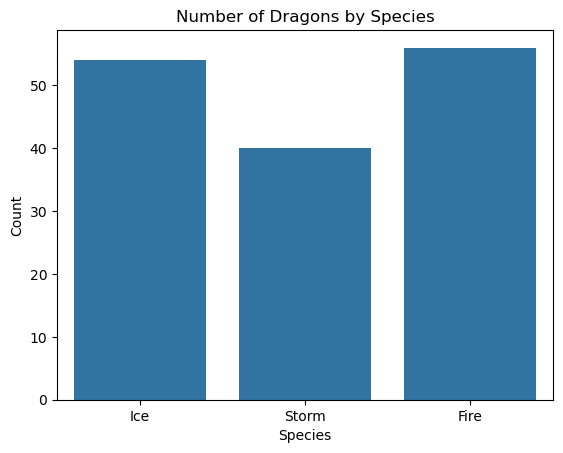

species
Fire     56
Ice      54
Storm    40
Name: count, dtype: int64


In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=dragons, x="species")
plt.title("Number of Dragons by Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

print(dragons["species"].value_counts())

<div dir="rtl">

### ملاحظتي (countplot)
توقعي كان قريب لكنه غير دقيق لعدد فاير (Fire) وظهر 56 تنين (توقعي كان 50)، بس ما كان دقيق لباقي الأنواع؛ لان عدد أيس (Ice) بلغ 54 وستورم (Storm) وصل إلى 40. الرسمة أوضحت أن Fire هو الأكثر عددا (56)، ثم Ice (54)، ثم Storm (40)، وهذا يتوافق مع احتمالات الاختيار داخل الكود

</div>

<div dir="rtl">

### توقعي (boxplot)
أتوقع ان يكون ستورم (Storm) صاحب اطول اجهزة او اجنحة بمتوسط يقارب 18 متر، يليه فاير (Fire) بحوالي 14 متر، ثم أيس (Ice) بحوالي 11 متر. وأتوقع فيه قيمة شاذة واضحة طول جناحها 140 متر، لانها اكبر بكثير من باقي القيم

</div>

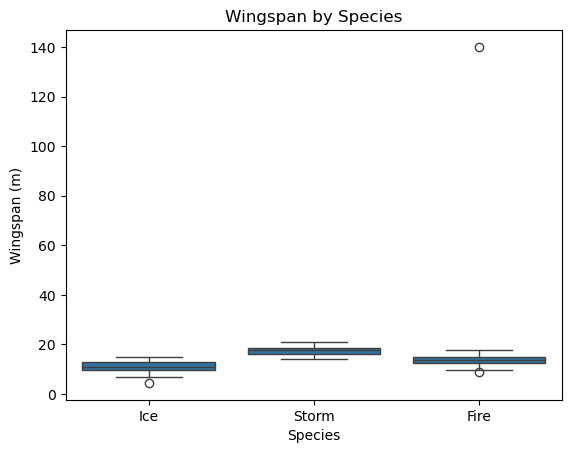

species
Fire     13.85
Ice      11.00
Storm    17.60
Name: wingspan_m, dtype: float64
dragon_id       D037
species         Fire
wingspan_m     140.0
fire_temp_c      977
age_years        231
weight_t        10.0
Name: 37, dtype: object


In [16]:
sns.boxplot(data=dragons, x="species", y="wingspan_m")
plt.title("Wingspan by Species")
plt.xlabel("Species")
plt.ylabel("Wingspan (m)")
plt.show()

print(dragons.groupby("species")["wingspan_m"].median())
print(dragons.loc[37])

<div dir="rtl">

### ملاحظتي (boxplot)
توقعي صحيح الرسمة بينت ان ستورم (Storm) يمتلك أطول أجنحة بوسيط 17.60 متر، يليه فاير (Fire) بوسيط 13.85 متر، ثم أيس (Ice) بوسيط 11.00 متر. وظهرت قيمة شاذة بطول 140 متر لتنين من نوع فاير، وهي غير منطقية لانها أكبر بحوالي 10 مرات من الوسيط، وزنه كان بس 10.0 مع ان المفروض يكون قريب من 84 لو كان طول جناحه 140 متر، لذلك شكل فيه خطأ في البيانات

</div>

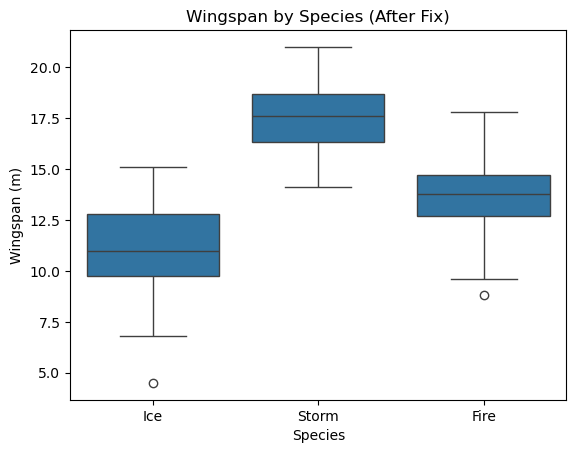

dragon_id       D037
species         Fire
wingspan_m     13.85
fire_temp_c      977
age_years        231
weight_t        10.0
Name: 37, dtype: object


In [17]:
fire_median = dragons.loc[dragons["species"] == "Fire", "wingspan_m"].median()
dragons.loc[37, "wingspan_m"] = fire_median

sns.boxplot(data=dragons, x="species", y="wingspan_m")
plt.title("Wingspan by Species (After Fix)")
plt.xlabel("Species")
plt.ylabel("Wingspan (m)")
plt.show()

print(dragons.loc[37])

<div dir="rtl">

### تنظيف البيانات
قمت بتصحيح قيمة طول الجناح للتنين (D037) من 140 إلى 13.85. اخترت اني استبدلها بوسيط نوع فاير (Fire) بدل ما أحذف السجل كله، لان باقي بيانات التنين زي العمر والوزن ودرجة النار كانت سليمة، وغير هذا الوسيط ما يتأثر بالقيم الشاذة ويعطي قيمة تعبر عن النوع بشكل أفضل. بعد هالتصحيح صارت الرسمة أوضح بكثير، واختفى التشويه اللي سببته قيمة 140، وصار الفرق الحقيقي بين أنواع التنانين أسهل للملاحظة والمقارنة

</div>

<div dir="rtl">

### توقعي (scatterplot)
أتوقع ان الأنواع الثلاثة تكون في مجموعات منفصلة عن بعض أكثر من إنها تكون مختلطة. وأتوقع ان فاير (Fire) يكون الأعلى حرارة بحوالي 900 درجة، وأيس (Ice) الأقل بحوالي 80 درجة، وستورم (Storm) في المنتصف بحوالي 300 درجة. وأتوقع وجود علاقة موجبة بسيطة داخل النوع الواحد، بحيث كلما زاد طول الجناح زادت حرارة النار شوي

</div>

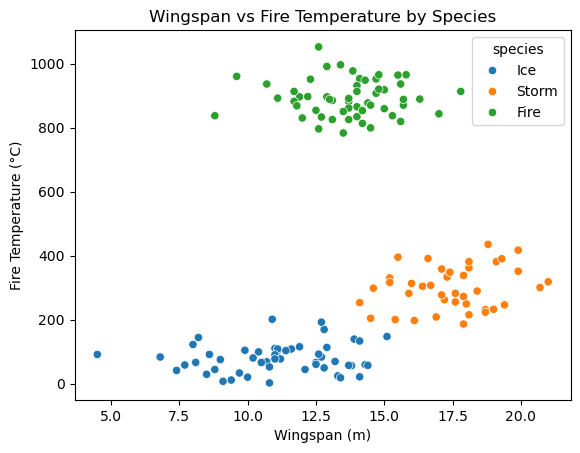

         wingspan_m  fire_temp_c
species                         
Fire      13.690179   893.535714
Ice       11.070370    79.185185
Storm     17.482500   298.225000


In [18]:
sns.scatterplot(data=dragons, x="wingspan_m", y="fire_temp_c", hue="species")
plt.title("Wingspan vs Fire Temperature by Species")
plt.xlabel("Wingspan (m)")
plt.ylabel("Fire Temperature (°C)")
plt.show()

print(dragons.groupby("species")[["wingspan_m", "fire_temp_c"]].mean())

<div dir="rtl">

### ملاحظتي (scatterplot)
توقعي صحيح من ناحية إن الأنواع ظهرت في مجموعات منفصلة وواضحة، وبلغ متوسط الحرارة لفاير (Fire) تقريباً 893.5 درجة، وستورم (Storm) حوالي 298.2 درجة، وأيس (Ice) تقريبا 79.2 درجة. توقعي بوجود علاقة موجبة بين طول الجناح والحرارة داخل النوع الواحد توقعي غير صحيح لان النقاط كانت مبعثرة وما تظهر أي علاقة واضحة. والرسمة وضحت ان الحرارة تعتمد أكثر على النوع نفسه؛ فمثلا ستورم عنده متوسط جناح أكبر (17.48 متر) مقارنة بفاير (13.69 متر)، ومع ذلك كانت حرارة فاير أعلى بكثير

</div>

<div dir="rtl">

### توقعي (heatmap)
أتوقع ان أقوى ارتباط يكون بين طول الجناح (`wingspan_m`) والوزن (`weight_t`) وبشكل موجب، لان الوزن يعتمد على طول الجناح في الكود وأتوقع ما يكون فيه ارتباط قوي بين العمر (`age_years`) وباقي الأعمدة، لان العمر تم توليده بشكل مستقل

</div>

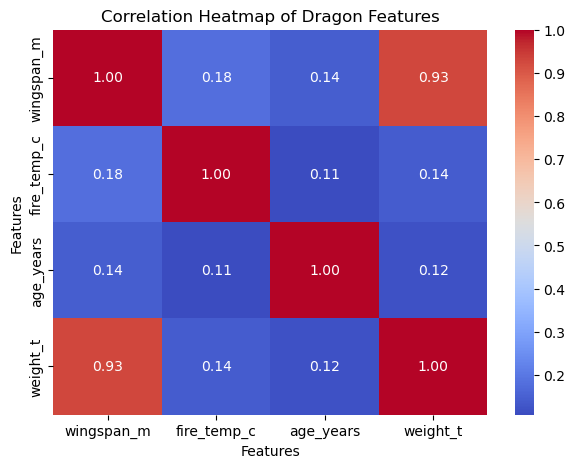

             wingspan_m  fire_temp_c  age_years  weight_t
wingspan_m     1.000000     0.181148   0.143999  0.927955
fire_temp_c    0.181148     1.000000   0.108170  0.142378
age_years      0.143999     0.108170   1.000000  0.119246
weight_t       0.927955     0.142378   0.119246  1.000000


In [19]:
corr = dragons[["wingspan_m", "fire_temp_c", "age_years", "weight_t"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Dragon Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.show()

print(corr)

<div dir="rtl">

### ملاحظتي (heatmap)
توقعي طلع صحيح أقوى ارتباط كان بين طول الجناح (`wingspan_m`) والوزن (`weight_t`) بقيمة 0.93، لان الاثنين يعبران عن حجم التنين. لكن أضعف ارتباط كان بين العمر (`age_years`) وحرارة النار (`fire_temp_c`) بقيمة 0.11، وما وصل الارتباط إلى 1.00 بسبب وجود ضجيج عشوائي في البيانات. وايضا ارتباط الجناح بالحرارة كان 0.18 بس، وهالشي يتوافق مع الـ scatterplot الي وضحت ان الحرارة مرتبطة بالنوع أكثر من طول الجناح

</div>

<div dir="rtl">

### قراري
بقرر أرسل تنانين فاير للتدفئة في الشتاء، لأن أهم شيء عندي هو حرارة النار وما يهم طول الجناح. الـ scatterplot بين أن متوسط حرارة فاير وصل إلى 893.5 درجة، وهو أعلى بكثير من ستورم (298.2) وأيس (79.2). والـ heatmap أوضح أن ارتباط طول الجناح بالحرارة ضعيف (0.18)، وعشان كذا ما أقدر أعتمد على حجم الجناح عشان أختار تنين للتدفئة. وفيه عدد كافي من تنانين فاير، بحيث الـ countplot أظهر أن عندنا 56 تنين من هالنوع، يعني أقدر أرسل تنينين بكل سهولة

أما النوع اللي مستحيل أرسله فهو أيس، لأن متوسط حرارته 79.2 درجة بس، وهو الأقل بين كل الأنواع، وبكذا ما بيكون مناسب أبداً للتدفئة مقارنة بفاير

ملاحظة عن البيانات: صححت قيمة جناح التنين D037 من 140 إلى 13.85 قبل التحليل، لأن القيمة الخطأ كانت ممكن تخرب الارتباطات والرسمات وتغير الاستنتاجات

</div>